<a href="https://colab.research.google.com/github/JonathanDP02/244107020197-Pembelajaran-Mesin/blob/main/JS14_Implementasi_Dataset_Praktikum_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv1D, MaxPooling1D,
    Flatten, Dense, Dropout
)
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Sleep_health_and_lifestyle_dataset(1).csv to Sleep_health_and_lifestyle_dataset(1).csv


In [3]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset(1).csv')

df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [4]:
print("Ukuran Dataset:", df.shape)

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Data Kosong:")
print(df.isnull().sum())

print("\nDistribusi Sleep Disorder:")
print(df['Sleep Disorder'].value_counts(dropna=False))

Ukuran Dataset: (374, 13)

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           155 non-null    object 
dtypes: float64(1), int64(7), object(5)

In [5]:
# Mengubah nilai kosong menjadi No Disorder
df['Sleep Disorder'] = df['Sleep Disorder'].fillna('No Disorder')

# Mengubah kategori menjadi angka
label_mapping = {
    'No Disorder': 0,
    'Insomnia': 1,
    'Sleep Apnea': 2
}

df['Target'] = df['Sleep Disorder'].map(label_mapping)

# Memisahkan fitur dan target
X = df.drop(columns=['Person ID', 'Sleep Disorder', 'Target'])
y = df['Target']

print("Distribusi Target:")
print(y.value_counts().sort_index())

print("\nJumlah Fitur:", X.shape[1])

Distribusi Target:
Target
0    219
1     77
2     78
Name: count, dtype: int64

Jumlah Fitur: 11


In [6]:
# Memisahkan tekanan darah
X[['Systolic BP', 'Diastolic BP']] = (
    X['Blood Pressure']
    .str.split('/', expand=True)
    .astype(float)
)

# Menghapus kolom Blood Pressure asli
X = X.drop(columns=['Blood Pressure'])

# Menentukan fitur kategorikal
categorical_features = [
    'Gender',
    'Occupation',
    'BMI Category'
]

# Menentukan fitur numerik
numerical_features = [
    col for col in X.columns
    if col not in categorical_features
]

print("Fitur Kategorikal:")
print(categorical_features)

print("\nFitur Numerik:")
print(numerical_features)

Fitur Kategorikal:
['Gender', 'Occupation', 'BMI Category']

Fitur Numerik:
['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic BP', 'Diastolic BP']


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah Data Training:", X_train.shape[0])
print("Jumlah Data Testing:", X_test.shape[0])

Jumlah Data Training: 299
Jumlah Data Testing: 75


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

# Fit hanya pada data training
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Mengubah hasil menjadi array jika masih berbentuk sparse matrix
if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

X_train_processed = X_train_processed.astype('float32')
X_test_processed = X_test_processed.astype('float32')

print("Shape Training:", X_train_processed.shape)
print("Shape Testing:", X_test_processed.shape)

Shape Training: (299, 24)
Shape Testing: (75, 24)


In [9]:
# Mengubah data menjadi format input CNN 1D
X_train_cnn = np.expand_dims(X_train_processed, axis=2)
X_test_cnn = np.expand_dims(X_test_processed, axis=2)

y_train = np.array(y_train)
y_test = np.array(y_test)

print("Shape X Training:", X_train_cnn.shape)
print("Shape X Testing:", X_test_cnn.shape)
print("Shape Y Training:", y_train.shape)

Shape X Training: (299, 24, 1)
Shape X Testing: (75, 24, 1)
Shape Y Training: (299,)


In [10]:
cnn = Sequential()

# Input Layer
cnn.add(Input(shape=(X_train_cnn.shape[1], 1)))

# Convolutional Layer pertama
cnn.add(Conv1D(
    filters=32,
    kernel_size=3,
    activation='relu',
    padding='same'
))

# Pooling Layer pertama
cnn.add(MaxPooling1D(pool_size=2))

# Convolutional Layer kedua
cnn.add(Conv1D(
    filters=64,
    kernel_size=3,
    activation='relu',
    padding='same'
))

# Pooling Layer kedua
cnn.add(MaxPooling1D(pool_size=2))

# Flatten Layer
cnn.add(Flatten())

# Fully Connected Layer
cnn.add(Dense(128, activation='relu'))

cnn.add(Dropout(0.3))

# Output Layer untuk tiga kelas
cnn.add(Dense(3, activation='softmax'))

cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 24, 32)         │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 12, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 12, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 6, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 384)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        49,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,003 (218.76 KB)

 Trainable params: 56,003 (218.76 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model berhasil dikompilasi!")

Model berhasil dikompilasi!


In [12]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
print(class_weights)

Class Weights:
{np.int64(0): np.float64(0.5695238095238095), np.int64(1): np.float64(1.60752688172043), np.int64(2): np.float64(1.60752688172043)}


In [13]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = cnn.fit(
    X_train_cnn,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.6611 - loss: 0.9623 - val_accuracy: 0.7333 - val_loss: 0.7950
Epoch 2/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8661 - loss: 0.6092 - val_accuracy: 0.8500 - val_loss: 0.5460
Epoch 3/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9038 - loss: 0.4520 - val_accuracy: 0.7167 - val_loss: 0.6692
Epoch 4/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8787 - loss: 0.4092 - val_accuracy: 0.8333 - val_loss: 0.5423
Epoch 5/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9163 - loss: 0.3872 - val_accuracy: 0.8500 - val_loss: 0.5824
Epoch 6/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9079 - loss: 0.3532 - val_accuracy: 0.8333 - val_loss: 0.6029
Epoch 7/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9205 - loss: 0.3380 - val_accuracy: 0.8333 - val_loss: 0.6019
Epoch 8/50
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9121 - loss: 0.3417 - val_accuracy: 0.8333 - v

In [14]:
loss, accuracy = cnn.evaluate(X_test_cnn, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8800 - loss: 0.4413
Test Loss: 0.4412705898284912
Test Accuracy: 0.8799999952316284
Test Accuracy (%): 87.99999952316284


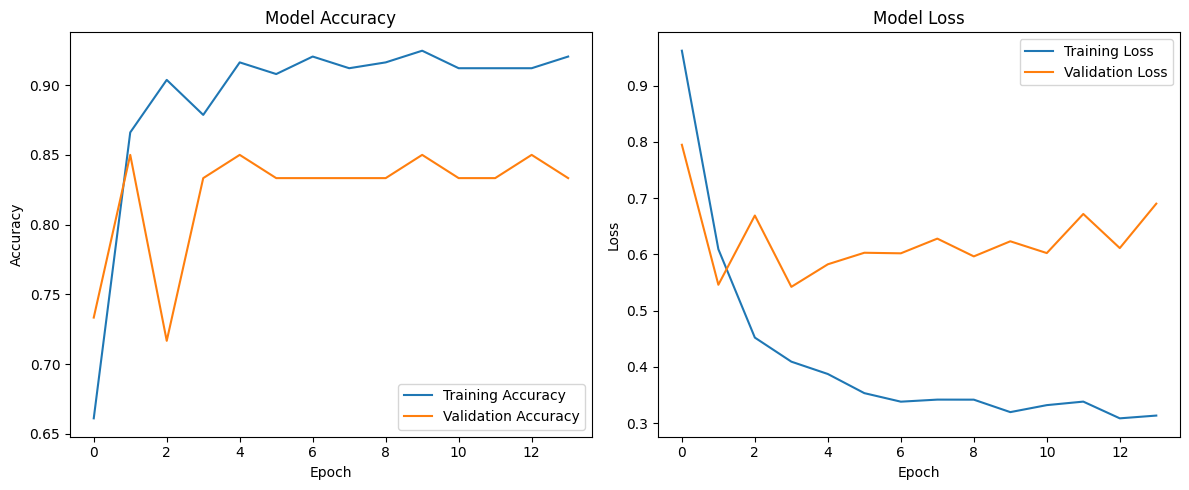

In [15]:
plt.figure(figsize=(12, 5))

# Grafik akurasi
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Grafik loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


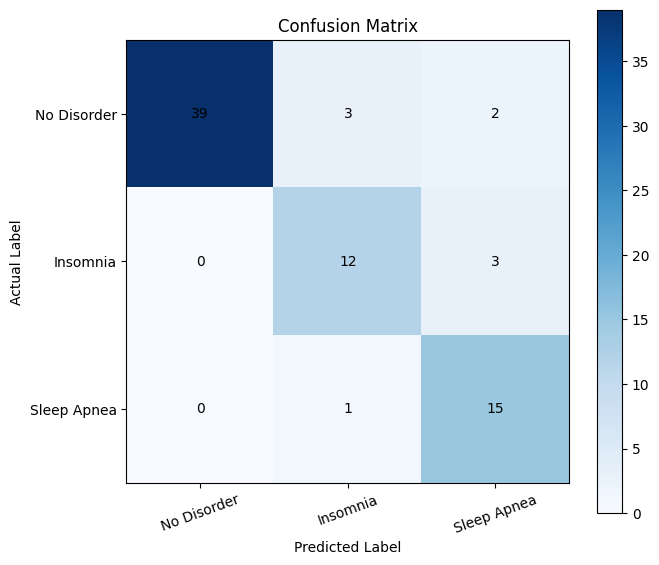

In [16]:
y_pred = cnn.predict(X_test_cnn)

# Mengambil kelas dengan probabilitas tertinggi
y_pred_class = np.argmax(y_pred, axis=1)

cm = confusion_matrix(
    y_test,
    y_pred_class,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

labels = ['No Disorder', 'Insomnia', 'Sleep Apnea']

plt.xticks([0, 1, 2], labels, rotation=20)
plt.yticks([0, 1, 2], labels)

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.colorbar()
plt.tight_layout()
plt.show()

In [17]:
print("Classification Report:")

print(classification_report(
    y_test,
    y_pred_class,
    labels=[0, 1, 2],
    target_names=[
        'No Disorder',
        'Insomnia',
        'Sleep Apnea'
    ],
    zero_division=0
))

Classification Report:
              precision    recall  f1-score   support

 No Disorder       1.00      0.89      0.94        44
    Insomnia       0.75      0.80      0.77        15
 Sleep Apnea       0.75      0.94      0.83        16

    accuracy                           0.88        75
   macro avg       0.83      0.87      0.85        75
weighted avg       0.90      0.88      0.88        75



In [18]:
# Mengambil satu data dari testing
sample = X_test.iloc[[0]]

# Preprocessing data
sample_processed = preprocessor.transform(sample)

if hasattr(sample_processed, "toarray"):
    sample_processed = sample_processed.toarray()

sample_processed = sample_processed.astype('float32')

# Mengubah format untuk CNN
sample_cnn = np.expand_dims(sample_processed, axis=2)

# Melakukan prediksi
prediction = cnn.predict(sample_cnn)

predicted_class = np.argmax(prediction, axis=1)[0]

class_names = {
    0: 'No Disorder',
    1: 'Insomnia',
    2: 'Sleep Apnea'
}

print("Hasil Prediksi:", class_names[predicted_class])
print("Probabilitas:", prediction[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
Hasil Prediksi: Insomnia
Probabilitas: [0.11868811 0.6079306  0.27338123]
